In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import seaborn as sns
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Dense, Input, BatchNormalization, Dropout
from keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nikhil7280/weather-type-classification/weather_classification_data.csv


In [2]:
df = pd.read_csv('/kaggle/input/datasets/nikhil7280/weather-type-classification/weather_classification_data.csv')

df = pd.get_dummies(df, columns=['Cloud Cover','Season','Location'])

le = LabelEncoder()
df['Weather Type'] = le.fit_transform(df['Weather Type'])

df.head()

,Temperature,Humidity,Wind Speed,Precipitation (%),Atmospheric Pressure,UV Index,Visibility (km),Weather Type,Cloud Cover_clear,Cloud Cover_cloudy,Cloud Cover_overcast,Cloud Cover_partly cloudy,Season_Autumn,Season_Spring,Season_Summer,Season_Winter,Location_coastal,Location_inland,Location_mountain
0,14.0,73,9.5,82.0,1010.82,2,3.5,1,False,False,False,True,False,False,False,True,False,True,False
1,39.0,96,8.5,71.0,1011.43,7,10.0,0,False,False,False,True,False,True,False,False,False,True,False
2,30.0,64,7.0,16.0,1018.72,5,5.5,3,True,False,False,False,False,True,False,False,False,False,True
3,38.0,83,1.5,82.0,1026.25,7,1.0,3,True,False,False,False,False,True,False,False,True,False,False
4,27.0,74,17.0,66.0,990.67,1,2.5,1,False,False,True,False,False,False,False,True,False,False,True


In [3]:
y = df['Weather Type']
x = df.drop('Weather Type', axis=1)

x = x.astype('float32')
y = y.astype('float32')

y = to_categorical(y)
y[1]

array([1., 0., 0., 0.])

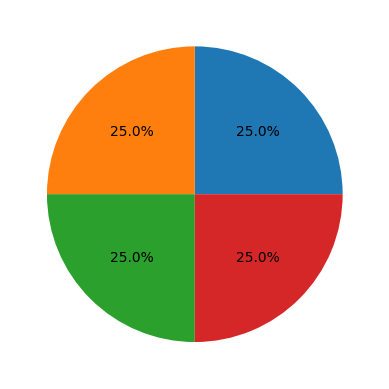

In [4]:
vc = df['Weather Type'].value_counts()
plt.pie(vc.values, autopct='%1.1f%%')
plt.show() # 25 25 25 25 :3 

In [5]:
x_train,x_test,y_train,y_test = train_test_split(
    x,y,train_size=0.8,random_state=42
)

In [6]:
scaler = MinMaxScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [7]:
model = Sequential()

model.add(Input(shape=(x_train.shape[1],)))
model.add(Dense(256, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Dense(64, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.3))

model.add(Dense(32, activation='relu'))
model.add(BatchNormalization())
model.add(Dropout(0.2))

model.add(Dense(4, activation='softmax'))

model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

model.fit(
    x_train_scaled,y_train,
    epochs=128,
    batch_size=128,
    validation_split=0.2,
)

Epoch 1/128


2026-09-27 20:10:25.890470: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


66/66 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.6863 - loss: 0.8427 - val_accuracy: 0.4143 - val_loss: 1.1418
Epoch 2/128
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8198 - loss: 0.5192 - val_accuracy: 0.3703 - val_loss: 1.1850
Epoch 3/128
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8608 - loss: 0.4245 - val_accuracy: 0.4498 - val_loss: 1.1971
Epoch 4/128
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8696 - loss: 0.3818 - val_accuracy: 0.5123 - val_loss: 1.1117
Epoch 5/128
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8783 - loss: 0.3510 - val_accuracy: 0.6416 - val_loss: 0.7863
Epoch 6/128
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8862 - loss: 0.3275 - val_accuracy: 0.8139 - val_loss: 0.4922
Epoch 7/128
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8866 - loss: 0.3147 - val_accuracy: 0.8958 - val_loss: 0.3131
Epoch 8/128
66/66 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8884 - loss: 0.3061 - val_accuracy: 0.8982 - val_loss: 0.

In [8]:
example = x.head(10).values

pred = model.predict(example)

np.argmax(pred, axis=1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step


array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [9]:
y_pred_probs = model.predict(x_test_scaled)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(np.array(y_test), axis=1)

83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


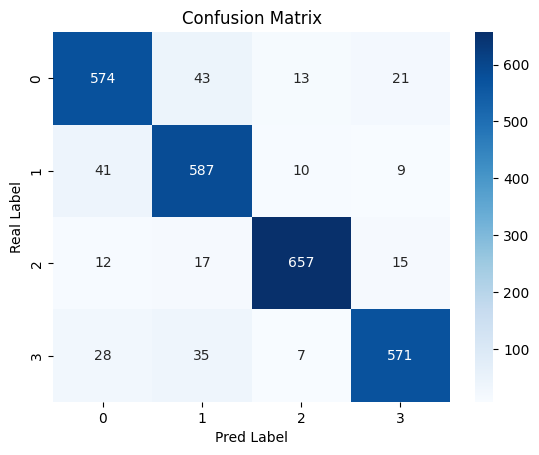

In [10]:
sns.heatmap(confusion_matrix(y_true, y_pred), cmap='Blues', annot=True, fmt='g')
plt.title('Confusion Matrix')
plt.ylabel('Real Label')
plt.xlabel('Pred Label')
plt.show()

In [11]:
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.88      0.88      0.88       651
           1       0.86      0.91      0.88       647
           2       0.96      0.94      0.95       701
           3       0.93      0.89      0.91       641

    accuracy                           0.90      2640
   macro avg       0.91      0.90      0.90      2640
weighted avg       0.91      0.90      0.91      2640

